# Import Libraries

In [ ]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# SweFAQ data load

In [2]:
swefaq_corpus = load_dataset("mteb/SweFaqRetrieval", "corpus")["test"]
swefaq_queries = load_dataset("mteb/SweFaqRetrieval", "queries")["test"]
swefaq_qrels = load_dataset("mteb/SweFaqRetrieval", "qrels")["test"]

print("SweFAQ documents:", len(swefaq_corpus))
print("SweFAQ queries:", len(swefaq_queries))
print("SweFAQ qrels:", len(swefaq_qrels))

SweFAQ documents: 511
SweFAQ queries: 513
SweFAQ qrels: 513


# SwednRetrieval data load

In [3]:
swedn_corpus = load_dataset("mteb/SwednRetrieval", "corpus")["test"]
swedn_queries = load_dataset("mteb/SwednRetrieval", "queries")["test"]
swedn_qrels = load_dataset("mteb/SwednRetrieval", "qrels")["test"]

print("SwednRetrieval documents:", len(swedn_corpus))
print("SwednRetrieval queries:", len(swedn_queries))
print("SwednRetrieval qrels:", len(swedn_qrels))

SwednRetrieval documents: 2046
SwednRetrieval queries: 1024
SwednRetrieval qrels: 2048


# Dataset Structure and Data Quality

In [4]:
datasets_info = {
    "SweFAQ": (swefaq_corpus, swefaq_queries, swefaq_qrels),
    "SwednRetrieval": (swedn_corpus, swedn_queries, swedn_qrels),
}

for name, (corpus, queries, qrels) in datasets_info.items():
    print(f"\n--- {name} ---")
    print("Corpus columns:", corpus.column_names)
    print("Query columns:", queries.column_names)
    print("Qrels columns:", qrels.column_names)

    print("\nCorpus example:", corpus[0])
    print("Query example:", queries[0])
    print("Qrels example:", qrels[0])


--- SweFAQ ---
Corpus columns: ['_id', 'text', 'title']
Query columns: ['_id', 'text']
Qrels columns: ['query-id', 'corpus-id', 'score']

Corpus example: {'_id': '1', 'text': 'Ja,  den som är gravid kan avstå några av sina föräldradagar till dig. Det är enklast att göra på Mina sidor.', 'title': ''}
Query example: {'_id': '0', 'text': 'Får jag lägre föräldrapenning om jag går ner i arbetstid innan förlossningen?'}
Qrels example: {'query-id': '0', 'corpus-id': '2', 'score': 1}

--- SwednRetrieval ---
Corpus columns: ['_id', 'text', 'title']
Query columns: ['_id', 'text']
Qrels columns: ['query-id', 'corpus-id', 'score']

Corpus example: {'_id': '1', 'text': 'Hård kritik mot Göran Lambertz från tunga och erfarna domare.Justitiekanslerns kritik mot domstolarna är till stora delar grundlös och hans slutsatser förhastade. Som argument för att ifrågasätta rättssäkerheten anför han de dömdas egna uppgifter att de är oskyldiga. Det är inte seriöst. När JK tjänstgjorde i domstol för 30 år seda

# Dataset Statistics

In [13]:
def get_dataset_stats(name, corpus, queries, qrels):
    corpus_df = corpus.to_pandas()
    queries_df = queries.to_pandas()
    qrels_df = qrels.to_pandas()

    text_col = "text"
    char_lengths = corpus_df[text_col].fillna("").astype(str).str.len()
    word_lengths = corpus_df[text_col].fillna("").astype(str).str.split().str.len()

    return {
        "Dataset": name,
        "Documents": len(corpus_df),
        "Queries": len(queries_df),
        "Qrel records": len(qrels_df),
        "Median chars/doc": char_lengths.median(),
        "Median words/doc": word_lengths.median(),
        "Mean words/doc": word_lengths.mean(),
        "90th percentile words": word_lengths.quantile(0.90),
        "Maximum words/doc": word_lengths.max(),
    }


stats = pd.DataFrame([
    get_dataset_stats(
        "SweFAQ", swefaq_corpus, swefaq_queries, swefaq_qrels
    ),
    get_dataset_stats(
        "SwednRetrieval",
        swedn_corpus, swedn_queries, swedn_qrels
    ),
])

display(stats.round(2))


,Dataset,Documents,Queries,Qrel records,Median chars/doc,Median words/doc,Mean words/doc,90th percentile words,Maximum words/doc
0,SweFAQ,511,513,513,263.0,44.0,52.52,104.0,283
1,SwednRetrieval,2046,1024,2048,916.5,133.5,455.57,1093.5,5783


# Data Quality Checks

In [15]:
def first_existing_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not find {description}. Available columns: {list(df.columns)}"
    )


def inspect_dataset_quality(name, corpus, queries, qrels):
    corpus_df = corpus.to_pandas()
    queries_df = queries.to_pandas()
    qrels_df = qrels.to_pandas()

    corpus_id_col = first_existing_column(
        corpus_df, ["_id", "corpus-id", "doc_id", "document_id", "id"],
        "corpus ID column"
    )
    query_id_col = first_existing_column(
        queries_df, ["_id", "query-id", "query_id", "id"],
        "query ID column"
    )
    qrels_query_col = first_existing_column(
        qrels_df, ["query-id", "query_id", "query_id"],
        "qrels query ID column"
    )
    qrels_corpus_col = first_existing_column(
        qrels_df, ["corpus-id", "corpus_id", "doc_id", "document_id"],
        "qrels corpus/document ID column"
    )
    score_col = first_existing_column(
        qrels_df, ["score", "relevance", "label"],
        "qrels relevance-score column"
    )

    # Normalize IDs to strings before checking references.
    corpus_ids = set(corpus_df[corpus_id_col].dropna().astype(str))
    query_ids = set(queries_df[query_id_col].dropna().astype(str))
    qrel_query_ids = qrels_df[qrels_query_col].dropna().astype(str)
    qrel_corpus_ids = qrels_df[qrels_corpus_col].dropna().astype(str)

    scores = pd.to_numeric(qrels_df[score_col], errors="coerce")
    relevant_mask = scores > 0
    relevant_qrels = qrels_df.loc[relevant_mask].copy()
    relevant_query_ids = set(
        relevant_qrels[qrels_query_col].dropna().astype(str)
    )

    print(f"\n--- {name}: data quality ---")
    print("Duplicate corpus IDs:", corpus_df[corpus_id_col].duplicated().sum())
    print("Duplicate query IDs:", queries_df[query_id_col].duplicated().sum())
    print("Duplicate qrels rows:", qrels_df.duplicated().sum())
    print("Missing values — corpus:", int(corpus_df.isna().sum().sum()))
    print("Missing values — queries:", int(queries_df.isna().sum().sum()))
    print("Missing values — qrels:", int(qrels_df.isna().sum().sum()))
    print(
        "Empty document texts:",
        int(corpus_df["text"].fillna("").astype(str).str.strip().eq("").sum())
    )
    print(
        "Empty query texts:",
        int(queries_df["text"].fillna("").astype(str).str.strip().eq("").sum())
    )
    print("Queries with >=1 relevant document:", len(relevant_query_ids))
    print(
        "Queries with no relevant qrels:",
        len(query_ids - relevant_query_ids)
    )
    print("Relevant qrels (score > 0):", int(relevant_mask.sum()))
    print(
        "Qrels referencing unknown query IDs:",
        len(set(qrel_query_ids) - query_ids)
    )
    print(
        "Qrels referencing unknown document IDs:",
        len(set(qrel_corpus_ids) - corpus_ids)
    )
    print("Relevance-score distribution:")
    display(scores.value_counts(dropna=False).sort_index().rename_axis("score").to_frame("qrel_count"))

    relevant_per_query = (
        relevant_qrels.groupby(qrels_query_col)[qrels_corpus_col]
        .nunique()
    )
    if len(relevant_per_query):
        print("Relevant documents per query (among queries with relevance):")
        display(relevant_per_query.describe().to_frame("relevant_docs_per_query").round(2))

    return {
        "Dataset": name,
        "Documents": len(corpus_df),
        "Queries": len(queries_df),
        "Queries with relevant docs": len(relevant_query_ids),
        "Relevant qrels": int(relevant_mask.sum()),
        "Unknown query references": len(set(qrel_query_ids) - query_ids),
        "Unknown document references": len(set(qrel_corpus_ids) - corpus_ids),
    }


quality_summaries = []
for name, (corpus, queries, qrels) in datasets_info.items():
    quality_summaries.append(
        inspect_dataset_quality(name, corpus, queries, qrels)
    )

quality_summary_df = pd.DataFrame(quality_summaries)
display(quality_summary_df)



--- SweFAQ: data quality ---
Duplicate corpus IDs: 0
Duplicate query IDs: 0
Duplicate qrels rows: 0
Missing values — corpus: 0
Missing values — queries: 0
Missing values — qrels: 0
Empty document texts: 0
Empty query texts: 0
Queries with >=1 relevant document: 513
Queries with no relevant qrels: 0
Relevant qrels (score > 0): 513
Qrels referencing unknown query IDs: 0
Qrels referencing unknown document IDs: 0
Relevance-score distribution:


,qrel_count
score,
1,513


Relevant documents per query (among queries with relevance):


,relevant_docs_per_query
count,513.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0



--- SwednRetrieval: data quality ---
Duplicate corpus IDs: 0
Duplicate query IDs: 0
Duplicate qrels rows: 0
Missing values — corpus: 0
Missing values — queries: 0
Missing values — qrels: 0
Empty document texts: 0
Empty query texts: 0
Queries with >=1 relevant document: 1024
Queries with no relevant qrels: 0
Relevant qrels (score > 0): 2048
Qrels referencing unknown query IDs: 0
Qrels referencing unknown document IDs: 0
Relevance-score distribution:


,qrel_count
score,
1,2048


Relevant documents per query (among queries with relevance):


,relevant_docs_per_query
count,1024.0
mean,2.0
std,0.0
min,2.0
25%,2.0
50%,2.0
75%,2.0
max,2.0


,Dataset,Documents,Queries,Queries with relevant docs,Relevant qrels,Unknown query references,Unknown document references
0,SweFAQ,511,513,513,513,0,0
1,SwednRetrieval,2046,1024,1024,2048,0,0


## Figure 1. Document-length distribution (ECDF)

An empirical cumulative distribution function (ECDF) shows the proportion of documents at or below each length. The x-axis is logarithmic because document lengths are often strongly right-skewed.

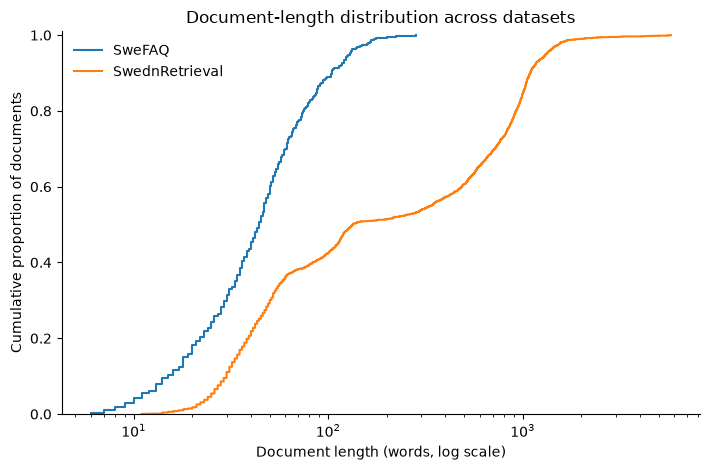

In [9]:
# Word counts
swefaq_word_lengths = np.asarray([
    len(doc['text'].split()) for doc in swefaq_corpus
])
swedn_word_lengths = np.asarray([
    len(doc['text'].split()) for doc in swedn_corpus
])

def plot_ecdf(values, label):
    values = np.sort(values[values > 0])
    y = np.arange(1, len(values) + 1) / len(values)
    plt.step(values, y, where='post', label=label)

fig, ax = plt.subplots(figsize=(7.2, 4.8))

plot_ecdf(swefaq_word_lengths, 'SweFAQ')
plot_ecdf(swedn_word_lengths, 'SwednRetrieval')

ax.set_xscale('log')
ax.set_xlabel('Document length (words, log scale)')
ax.set_ylabel('Cumulative proportion of documents')
ax.set_title('Document-length distribution across datasets')
ax.set_ylim(0, 1.01)

# Remove background grid
ax.grid(False)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

## Figure 2. Document-length summary (boxplot)

The boxplot summarizes the median and spread of document lengths. The logarithmic y-axis helps display short and long documents together. Figure 1: the ECDF shows the overall distribution, while the boxplot provides a compact summary.

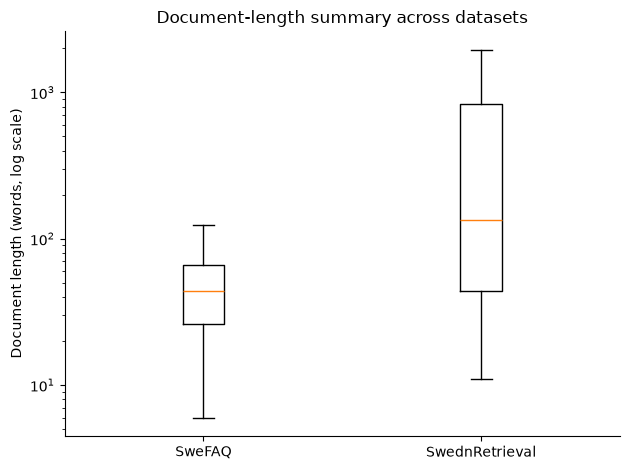

,Dataset,Documents,Median words,Mean words,90th percentile words,Maximum words
0,SweFAQ,511,44.0,52.52,104.0,283
1,SwednRetrieval,2046,133.5,455.57,1093.5,5783


In [12]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))

ax.boxplot(
    [swefaq_word_lengths, swedn_word_lengths],
    tick_labels=['SweFAQ', 'SwednRetrieval'],
    showfliers=False
)

ax.set_ylabel('Document length (words, log scale)')
ax.set_title('Document-length summary across datasets')
ax.set_yscale('log')

# Remove background grid
ax.grid(False)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


# Summary table (unchanged)
length_summary = pd.DataFrame({
    'Dataset': ['SweFAQ', 'SwednRetrieval'],
    'Documents': [
        len(swefaq_word_lengths),
        len(swedn_word_lengths)
    ],
    'Median words': [
        np.median(swefaq_word_lengths),
        np.median(swedn_word_lengths)
    ],
    'Mean words': [
        np.mean(swefaq_word_lengths),
        np.mean(swedn_word_lengths)
    ],
    '90th percentile words': [
        np.percentile(swefaq_word_lengths, 90),
        np.percentile(swedn_word_lengths, 90)
    ],
    'Maximum words': [
        np.max(swefaq_word_lengths),
        np.max(swedn_word_lengths)
    ]
})

display(length_summary.round(2))